In [1]:
import OMPython
import os
import logging
import pandas as pd
import DyMat
import numpy as np
from matplotlib import pyplot as plt

In [2]:
logging.getLogger("OMPython").setLevel(logging.ERROR)
omc = OMPython.OMCSessionLocal()
omc.sendExpression("loadFile(\"/home/wspark/projects/ThermoPower/ThermoPower/package.mo\")")
omc.sendExpression("loadFile(\"/home/wspark/projects/AmazonRunScripts/ReferenceOM/package.mo\")")
RESULT_DIR = "/home/wspark/projects/OMResults/freq_amp_analysis"
omc.sendExpression(f'cd("{RESULT_DIR}")')

'/home/wspark/projects/OMResults/freq_amp_analysis'

In [3]:
"Simulation setting"

var_map_PID = {
    "T_helium": "sens_T_He.T",
    "T_steam": "sens_T_steam.T",
    "P_steam": "sens_P_steam.p",
    "f_grid": "sens_frequency.f",
    "V_condenser": "Condenser.condenserShell.ratio_VvVtot",
    "rho_tot": "reactorPower_Avg.rho",
    "rho_Xe": "reactorPower_Avg.rho_Xe",
    "rho_ext": "reactorPower_Avg.rho_ext",
    "rho_feedback": "reactorPower_Avg.rho_feedback",
    "P_mech": "generator.Pm",
    "P_elec": "generator.Pe",
    "P_reactor": "reactorPower_Avg.P",
    "P_demand": "LoadDemand.y",
    "rho_der_y": "RhoDerivative.y",
    "T_fuel_hot": "Fuel_mixture_Hot.Tmax",
    "T_fuel_avg": "Fuel_mixture_Avg.Tmax",
    "PID_blower_y": "PID_blower.y",
    "PID_fwpp_y": "PID_fwpp.y",
    "PID_cdpp_y": "PID_cdpp.y",
    "PID_reactivity_y": "PID_reactivity.y",
    "PID_valve_y": "PID_valve.y",
}

var_map_SMC = {
    "T_helium": "sens_T_He.T",
    "T_steam": "sens_T_steam.T",
    "P_steam": "sens_P_steam.p",
    "f_grid": "sens_frequency.f",
    "V_condenser": "Condenser.condenserShell.ratio_VvVtot",
    "rho_tot": "reactorPower_Avg.rho",
    "rho_Xe": "reactorPower_Avg.rho_Xe",
    "rho_ext": "reactorPower_Avg.rho_ext",
    "rho_feedback": "reactorPower_Avg.rho_feedback",
    "P_mech": "generator.Pm",
    "P_elec": "generator.Pe",
    "P_reactor": "reactorPower_Avg.P",
    "P_demand": "LoadDemand.y",
    "rho_der_y": "RhoDerivative.y",
    "T_fuel_hot": "Fuel_mixture_Hot.Tmax",
    "T_fuel_avg": "Fuel_mixture_Avg.Tmax",
    "SMC_blower_y": "SMC_blower.y",
    "SMC_fwpp_y": "SMC_fwpp.y",
    "SMC_cdpp_y": "SMC_cdpp.y",
    "SMC_reactivity_y": "SMC_reactivity.y",
    "SMC_valve_y": "SMC_valve.y",
}

VARS_TO_SAVE_PID = list(var_map_PID.values())
VARIABLE_FILTER_PID = "|".join(VARS_TO_SAVE_PID)
VARS_TO_SAVE_SMC = list(var_map_SMC.values())
VARIABLE_FILTER_SMC = "|".join(VARS_TO_SAVE_SMC)

NUMOFCYCLE = 20
NUMOFANALYSISCYCLE = 3
NUMOFPOINT = 30
STARTTIME = 0
SINESTARTTIME = 3000

NOMINALPOWER = 0.5
NOMINAL_T_STEAM = 823
NOMINAL_P_STEAM = 14.3e6
NOMINAL_T_HELIUM = 1023
NOMINAL_F_GRID = 60
NOMINAL_P_DEMAND = 65.5e6

AMPLITUDE = [
    0.02,
    0.05,
    0.1,
    0.15,
    0.2,
]
PERIOD = [
    0.2,
    1,
    5,
    10,
    15,
    20,
    25,
    30,
    35,
    40,
    45,
    50,
    55,
    60,
    90,
    120,
    150,
    300
]

MODEL_PID = "ReferenceOM.Characterization.freq_amp_PID"
MODEL_SMC = "ReferenceOM.Characterization.freq_amp_SMC"

In [ ]:
"Run PID cases"

for amp in AMPLITUDE:
    for period in PERIOD:
        freq = 1/period
        case_name = (
            f"sine_A{amp:.2f}"
            f"_T{period:.1f}s"
            "_PID"
        )

        STOPTIME = SINESTARTTIME + period*NUMOFCYCLE
        DT = period/NUMOFPOINT
        NUMOFINTERVAL = int((STOPTIME-STARTTIME)/DT)

        print(
            f"Running {case_name}"
        )

        result = omc.sendExpression(f"""
        simulate(
            {MODEL_PID},
            stopTime={STOPTIME},
            numberOfIntervals={NUMOFINTERVAL},
            tolerance=1e-6,
            outputFormat="mat",
            fileNamePrefix="{case_name}",
            variableFilter="{VARIABLE_FILTER_PID}",
            simflags="-override=LoadDemand.amplitude={amp},LoadDemand.freqHz={freq},LoadDemand.offset={NOMINALPOWER},LoadDemand.startTime={SINESTARTTIME}"
        )
        """)
        print("  ->", result["resultFile"])

for filename in os.listdir(RESULT_DIR):
    path = os.path.join(RESULT_DIR, filename)
    if os.path.isfile(path) and not filename.endswith(".mat"):
        os.remove(path)

saved_vars = omc.sendExpression(
    f'readSimulationResultVars("{result["resultFile"]}", false)'
)

for v in saved_vars:
    print(v)

In [ ]:
"Run SMC cases"

for amp in AMPLITUDE:
    for period in PERIOD:
        freq = 1/period
        # amp_eff = NOMINALPOWER*amp
        case_name = (
            f"sine_A{amp:.2f}"
            f"_T{period:.1f}s"
            "_SMC"
        )

        STOPTIME = SINESTARTTIME + period*NUMOFCYCLE
        DT = period/NUMOFPOINT
        NUMOFINTERVAL = int((STOPTIME-STARTTIME)/DT)

        print(
            f"Running {case_name}"
        )

        result = omc.sendExpression(f"""
        simulate(
            {MODEL_SMC},
            stopTime={STOPTIME},
            numberOfIntervals={NUMOFINTERVAL},
            tolerance=1e-6,
            outputFormat="mat",
            fileNamePrefix="{case_name}",
            variableFilter="{VARIABLE_FILTER_SMC}",
            simflags="-override=LoadDemand.amplitude={amp},LoadDemand.freqHz={freq},LoadDemand.offset={NOMINALPOWER},LoadDemand.startTime={SINESTARTTIME}"
        )
        """)
        print("  ->", result["resultFile"])

for filename in os.listdir(RESULT_DIR):
    path = os.path.join(RESULT_DIR, filename)
    if os.path.isfile(path) and not filename.endswith(".mat"):
        os.remove(path)

saved_vars = omc.sendExpression(
    f'readSimulationResultVars("{result["resultFile"]}", false)'
)

for v in saved_vars:
    print(v)

In [4]:
"Load PID and SMC results .mat"

data_PID = {}
for amp in AMPLITUDE:
    for period in PERIOD:

        case_name = (
            f"sine_A{amp:.2f}"
            f"_T{period:.1f}s"
            "_PID"
        )
        mat = DyMat.DyMatFile(RESULT_DIR + "/" + case_name + "_res.mat")
        time = mat.abscissa("sens_T_He.T", valuesOnly=True)
        time_analysis = SINESTARTTIME+period*(NUMOFCYCLE-NUMOFANALYSISCYCLE)
        idx_trim = time >= time_analysis
        time_trim = time[idx_trim]-time_analysis

        data_PID[case_name] = {}
        data_PID[case_name]["T"] = time_trim/period
        data_PID[case_name]["time"] = time_trim

        for name, omname in var_map_PID.items():
            data_PID[case_name][name] = mat.data(omname)[idx_trim]
            
        data_PID[case_name]["T_helium_dev"] = data_PID[case_name]["T_helium"]-NOMINAL_T_HELIUM
        data_PID[case_name]["T_steam_dev"] = data_PID[case_name]["T_steam"]-NOMINAL_T_STEAM
        data_PID[case_name]["P_steam_dev"] = data_PID[case_name]["P_steam"]-NOMINAL_P_STEAM
        data_PID[case_name]["f_grid_dev"] = data_PID[case_name]["f_grid"]-NOMINAL_F_GRID
        data_PID[case_name]["P_mech_dev"] = data_PID[case_name]["P_mech"]-data_PID[case_name]["P_demand"]*NOMINAL_P_DEMAND
        data_PID[case_name]["P_elec_dev"] = data_PID[case_name]["P_elec"]-data_PID[case_name]["P_demand"]*NOMINAL_P_DEMAND
        data_PID[case_name]["P_inertia_dev"] = data_PID[case_name]["P_elec"]-data_PID[case_name]["P_mech"]

data_SMC = {}
for amp in AMPLITUDE:
    for period in PERIOD:

        case_name = (
            f"sine_A{amp:.2f}"
            f"_T{period:.1f}s"
            "_SMC"
        )
        mat = DyMat.DyMatFile(RESULT_DIR + "/" + case_name + "_res.mat")
        time = mat.abscissa("sens_T_He.T", valuesOnly=True)
        time_analysis = SINESTARTTIME+period*(NUMOFCYCLE-NUMOFANALYSISCYCLE)
        idx_trim = time >= time_analysis
        time_trim = time[idx_trim]-time_analysis

        data_SMC[case_name] = {}
        data_SMC[case_name]["T"] = time_trim/period
        data_SMC[case_name]["time"] = time_trim

        for name, omname in var_map_SMC.items():
            data_SMC[case_name][name] = mat.data(omname)[idx_trim]
            
        data_SMC[case_name]["T_helium_dev"] = data_SMC[case_name]["T_helium"]-NOMINAL_T_HELIUM
        data_SMC[case_name]["T_steam_dev"] = data_SMC[case_name]["T_steam"]-NOMINAL_T_STEAM
        data_SMC[case_name]["P_steam_dev"] = data_SMC[case_name]["P_steam"]-NOMINAL_P_STEAM
        data_SMC[case_name]["f_grid_dev"] = data_SMC[case_name]["f_grid"]-NOMINAL_F_GRID
        data_SMC[case_name]["P_mech_dev"] = data_SMC[case_name]["P_mech"]-data_SMC[case_name]["P_demand"]*NOMINAL_P_DEMAND
        data_SMC[case_name]["P_elec_dev"] = data_SMC[case_name]["P_elec"]-data_SMC[case_name]["P_demand"]*NOMINAL_P_DEMAND
        data_SMC[case_name]["P_inertia_dev"] = data_SMC[case_name]["P_elec"]-data_SMC[case_name]["P_mech"]

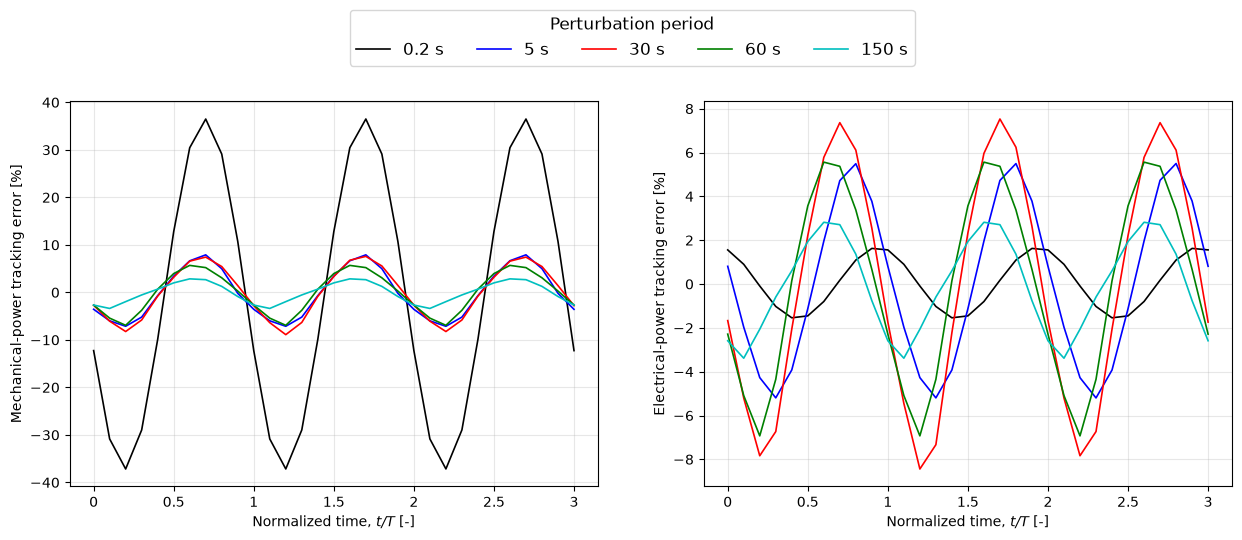

In [5]:
"Generate P_mech vs P_elec graph"

figs, axs = plt.subplots(1, 2, figsize=(15,5))

plt.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})

axs[0].plot(data_PID["sine_A0.20_T0.2s_PID"]["T"], data_PID["sine_A0.20_T0.2s_PID"]["P_mech_dev"]/(NOMINALPOWER*NOMINAL_P_DEMAND)*100, lw=1.2, color='k', label="0.2 s")
axs[0].plot(data_PID["sine_A0.20_T5.0s_PID"]["T"], data_PID["sine_A0.20_T5.0s_PID"]["P_mech_dev"]/(NOMINALPOWER*NOMINAL_P_DEMAND)*100, lw=1.2, color='b', label="5 s")
axs[0].plot(data_PID["sine_A0.20_T30.0s_PID"]["T"], data_PID["sine_A0.20_T30.0s_PID"]["P_mech_dev"]/(NOMINALPOWER*NOMINAL_P_DEMAND)*100, lw=1.2, color='r', label="30 s")
axs[0].plot(data_PID["sine_A0.20_T60.0s_PID"]["T"], data_PID["sine_A0.20_T60.0s_PID"]["P_mech_dev"]/(NOMINALPOWER*NOMINAL_P_DEMAND)*100, lw=1.2, color='g', label="60 s")
axs[0].plot(data_PID["sine_A0.20_T150.0s_PID"]["T"], data_PID["sine_A0.20_T150.0s_PID"]["P_mech_dev"]/(NOMINALPOWER*NOMINAL_P_DEMAND)*100, lw=1.2, color='c', label="150 s")
axs[0].grid(alpha=0.3)
axs[0].set_xlabel("Normalized time, $\\it{t/T}$ [-]")
axs[0].set_ylabel("Mechanical-power tracking error [%]")
axs[0].set_xticks([0, 0.5, 1, 1.5, 2, 2.5, 3])
axs[0].set_xticklabels(["0", "0.5", "1", "1.5", "2", "2.5", "3"])

axs[1].plot(data_PID["sine_A0.20_T0.2s_PID"]["T"], data_PID["sine_A0.20_T0.2s_PID"]["P_elec_dev"]/(NOMINALPOWER*NOMINAL_P_DEMAND)*100, lw=1.2, color='k', label="0.2 s")
axs[1].plot(data_PID["sine_A0.20_T5.0s_PID"]["T"], data_PID["sine_A0.20_T5.0s_PID"]["P_elec_dev"]/(NOMINALPOWER*NOMINAL_P_DEMAND)*100, lw=1.2, color='b', label="5 s")
axs[1].plot(data_PID["sine_A0.20_T30.0s_PID"]["T"], data_PID["sine_A0.20_T30.0s_PID"]["P_elec_dev"]/(NOMINALPOWER*NOMINAL_P_DEMAND)*100, lw=1.2, color='r', label="30 s")
axs[1].plot(data_PID["sine_A0.20_T60.0s_PID"]["T"], data_PID["sine_A0.20_T60.0s_PID"]["P_elec_dev"]/(NOMINALPOWER*NOMINAL_P_DEMAND)*100, lw=1.2, color='g', label="60 s")
axs[1].plot(data_PID["sine_A0.20_T150.0s_PID"]["T"], data_PID["sine_A0.20_T150.0s_PID"]["P_elec_dev"]/(NOMINALPOWER*NOMINAL_P_DEMAND)*100, lw=1.2, color='c', label="150 s")
axs[1].grid(alpha=0.3)
axs[1].set_xlabel("Normalized time, $\\it{t/T}$ [-]")
axs[1].set_ylabel("Electrical-power tracking error [%]")
axs[1].set_xticks([0, 0.5, 1, 1.5, 2, 2.5, 3])
axs[1].set_xticklabels(["0", "0.5", "1", "1.5", "2", "2.5", "3"])


handles, labels = axs[0].get_legend_handles_labels()
figs.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.08),
    ncol=5,
    frameon=True,
    title="Perturbation period",
    title_fontsize=12
)

# figs.savefig("sine_mech_elec.pdf", bbox_inches="tight")

In [ ]:
"Set heatmap figure"

T_steam_map_PID = np.zeros((len(AMPLITUDE), len(PERIOD)))
P_steam_map_PID = np.zeros((len(AMPLITUDE), len(PERIOD)))
T_helium_map_PID= np.zeros((len(AMPLITUDE), len(PERIOD)))
f_grid_map_PID= np.zeros((len(AMPLITUDE), len(PERIOD)))
P_mech_map_PID= np.zeros((len(AMPLITUDE), len(PERIOD)))
P_elec_map_PID= np.zeros((len(AMPLITUDE), len(PERIOD)))
P_inertia_map_PID= np.zeros((len(AMPLITUDE), len(PERIOD)))

T_steam_map_SMC = np.zeros((len(AMPLITUDE), len(PERIOD)))
P_steam_map_SMC = np.zeros((len(AMPLITUDE), len(PERIOD)))
T_helium_map_SMC= np.zeros((len(AMPLITUDE), len(PERIOD)))
f_grid_map_SMC= np.zeros((len(AMPLITUDE), len(PERIOD)))
P_mech_map_SMC= np.zeros((len(AMPLITUDE), len(PERIOD)))
P_elec_map_SMC= np.zeros((len(AMPLITUDE), len(PERIOD)))
P_inertia_map_SMC= np.zeros((len(AMPLITUDE), len(PERIOD)))

for i, amp in enumerate(AMPLITUDE):
    for j, period in enumerate(PERIOD):

        case_name_PID = (
            f"sine_A{amp:.2f}"
            f"_T{period:.1f}s"
            "_PID"
        )

        T_steam_dev_PID = data_PID[case_name_PID]["T_steam_dev"]
        P_steam_dev_PID = data_PID[case_name_PID]["P_steam_dev"]
        T_helium_dev_PID = data_PID[case_name_PID]["T_helium_dev"]
        f_grid_dev_PID = data_PID[case_name_PID]["f_grid_dev"]
        P_mech_dev_PID = data_PID[case_name_PID]["P_mech_dev"]
        P_elec_dev_PID = data_PID[case_name_PID]["P_elec_dev"]
        P_inertia_dev_PID = data_PID[case_name_PID]["P_inertia_dev"]


        T_steam_map_PID[i, j] = np.max(np.abs(T_steam_dev_PID))
        P_steam_map_PID[i, j] = np.max(np.abs(P_steam_dev_PID)/NOMINAL_P_STEAM)*100
        T_helium_map_PID[i, j] = np.max(np.abs(T_helium_dev_PID))
        f_grid_map_PID[i, j] = np.max(np.abs(f_grid_dev_PID))*1e3
        P_mech_map_PID[i, j] = np.max(np.abs(P_mech_dev_PID)/(NOMINALPOWER*NOMINAL_P_DEMAND))*100
        P_elec_map_PID[i, j] = np.max(np.abs(P_elec_dev_PID)/(NOMINALPOWER*NOMINAL_P_DEMAND))*100
        P_inertia_map_PID[i, j] = np.max(np.abs(P_inertia_dev_PID)/(NOMINALPOWER*NOMINAL_P_DEMAND))*100
        
        case_name_SMC = (
            f"sine_A{amp:.2f}"
            f"_T{period:.1f}s"
            "_SMC"
        )

        T_steam_dev_SMC = data_SMC[case_name_SMC]["T_steam_dev"]
        P_steam_dev_SMC = data_SMC[case_name_SMC]["P_steam_dev"]
        T_helium_dev_SMC = data_SMC[case_name_SMC]["T_helium_dev"]
        f_grid_dev_SMC = data_SMC[case_name_SMC]["f_grid_dev"]
        P_mech_dev_SMC = data_SMC[case_name_SMC]["P_mech_dev"]
        P_elec_dev_SMC = data_SMC[case_name_SMC]["P_elec_dev"]
        P_inertia_dev_SMC = data_SMC[case_name_SMC]["P_inertia_dev"]


        T_steam_map_SMC[i, j] = np.max(np.abs(T_steam_dev_SMC))
        P_steam_map_SMC[i, j] = np.max(np.abs(P_steam_dev_SMC)/NOMINAL_P_STEAM)*100
        T_helium_map_SMC[i, j] = np.max(np.abs(T_helium_dev_SMC))
        f_grid_map_SMC[i, j] = np.max(np.abs(f_grid_dev_SMC))*1e3
        P_mech_map_SMC[i, j] = np.max(np.abs(P_mech_dev_SMC)/(NOMINALPOWER*NOMINAL_P_DEMAND))*100
        P_elec_map_SMC[i, j] = np.max(np.abs(P_elec_dev_SMC)/(NOMINALPOWER*NOMINAL_P_DEMAND))*100
        P_inertia_map_SMC[i, j] = np.max(np.abs(P_inertia_dev_SMC)/(NOMINALPOWER*NOMINAL_P_DEMAND))*100

T_steam_min = min(T_steam_map_PID.min(), T_steam_map_SMC.min())
T_steam_max = max(T_steam_map_PID.max(), T_steam_map_SMC.max())
P_steam_min = min(P_steam_map_PID.min(), P_steam_map_SMC.min())
P_steam_max = max(P_steam_map_PID.max(), P_steam_map_SMC.max())
T_helium_min = min(T_helium_map_PID.min(), T_helium_map_SMC.min())
T_helium_max = max(T_helium_map_PID.max(), T_helium_map_SMC.max())
f_grid_min = min(f_grid_map_PID.min(), f_grid_map_SMC.min())
f_grid_max = max(f_grid_map_PID.max(), f_grid_map_SMC.max())
P_mech_min = min(P_mech_map_PID.min(), P_mech_map_SMC.min())
P_mech_max = max(P_mech_map_PID.max(), P_mech_map_SMC.max())
P_elec_min = min(P_elec_map_PID.min(), P_elec_map_SMC.min())
P_elec_max = max(P_elec_map_PID.max(), P_elec_map_SMC.max())

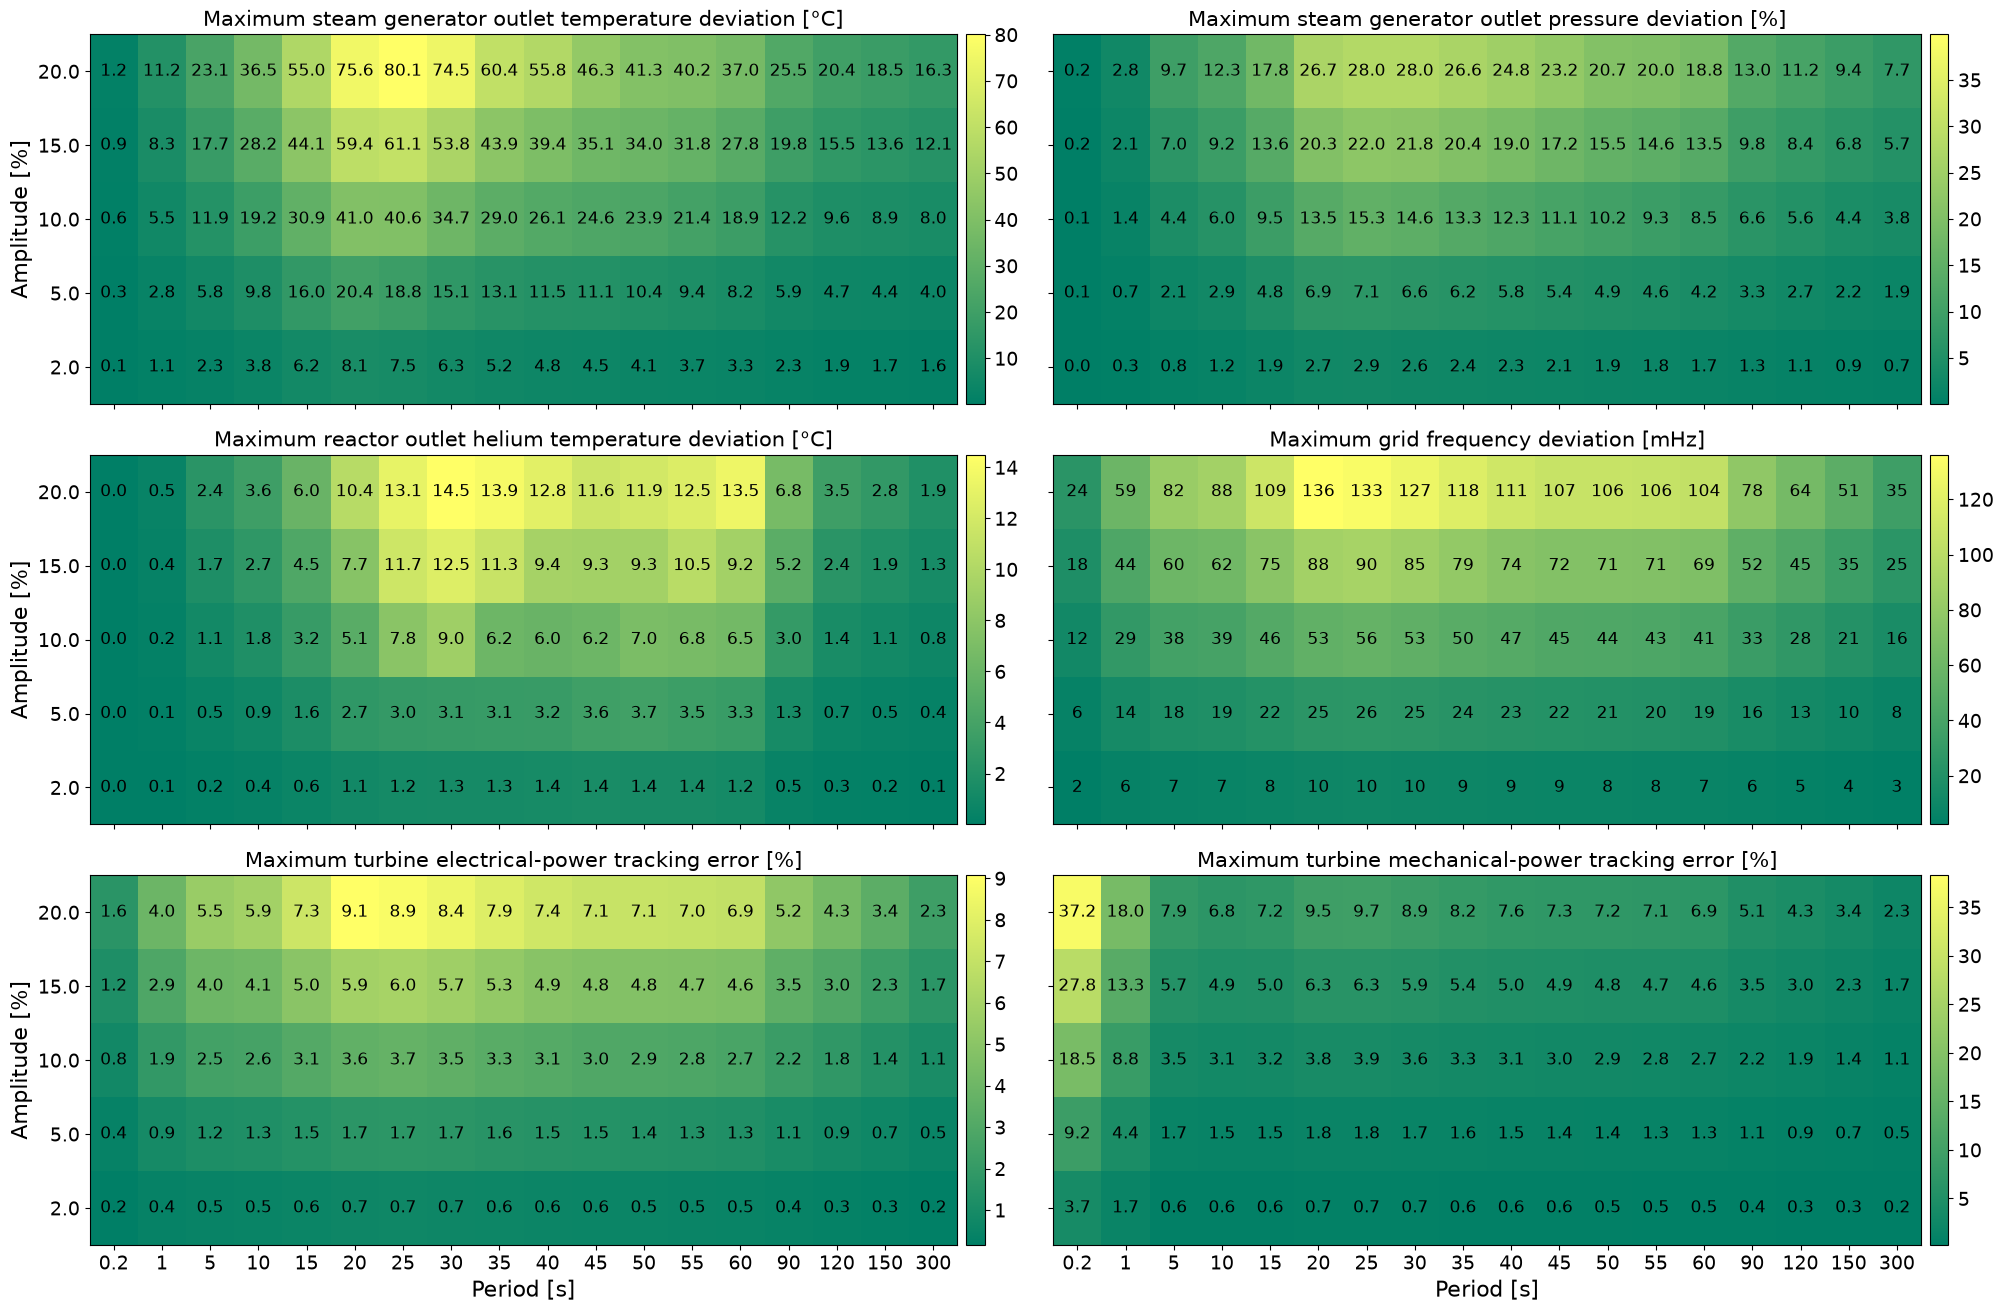

In [9]:
"Generate PID heatmap figure"

fig, axs = plt.subplots(
    3, 2,
    figsize=(20, 13),
    constrained_layout=True,
    sharex=True,
    sharey=True,
)

fig.set_constrained_layout_pads(
    w_pad=0.08,
    h_pad=0.04,
    wspace=0.03,
    hspace=0.05
)

plots = [
    (T_steam_map_PID,
     "Maximum steam generator outlet temperature deviation [$\\degree$C]",
     ".1f",
     T_steam_min,
     T_steam_max),

    (P_steam_map_PID,
     "Maximum steam generator outlet pressure deviation [%]",
     ".1f",
     P_steam_min,
     P_steam_max),

    (T_helium_map_PID,
     "Maximum reactor outlet helium temperature deviation [$\\degree$C]",
     ".1f",
     T_helium_min,
     T_helium_max),

    (f_grid_map_PID,
     "Maximum grid frequency deviation [mHz]",
     ".0f",
     f_grid_min,
     f_grid_max),

    (P_elec_map_PID,
     "Maximum turbine electrical-power tracking error [%]",
     ".1f",
     P_elec_min,
     P_elec_max),

    (P_mech_map_PID,
     "Maximum turbine mechanical-power tracking error [%]",
     ".1f",
     P_mech_min,
     P_mech_max),
]

for k, (ax, (data, title, fmt, vmin, vmax)) in enumerate(zip(axs.flat, plots)):

    im = ax.imshow(
        data,
        origin="lower",
        aspect="auto",
        cmap="summer",
        vmin=vmin,
        vmax=vmax,
    )

    ax.set_xticks(range(len(PERIOD)))
    ax.set_xticklabels(PERIOD, fontsize=14)

    ax.set_yticks(range(len(AMPLITUDE)))
    ax.set_yticklabels(
        np.array(AMPLITUDE) * 100,
        fontsize=14
    )

    ax.set_title(title, fontsize=15)
    if k in [4, 5]:
        ax.set_xlabel("Period [s]", fontsize=16)
    if k in [0, 2, 4]:
        ax.set_ylabel("Amplitude [%]", fontsize=16)
    cbar = fig.colorbar(
        im,
        ax=ax,
        pad=0.01
    )

    cbar.ax.tick_params(labelsize=14)

    for i in range(len(AMPLITUDE)):
        for j in range(len(PERIOD)):
            ax.text(
                j, i,
                f"{data[i,j]:{fmt}}",
                ha="center",
                va="center",
                fontsize=12,
                color="black"
            )

# fig.savefig("sine_PID.pdf", bbox_inches="tight")

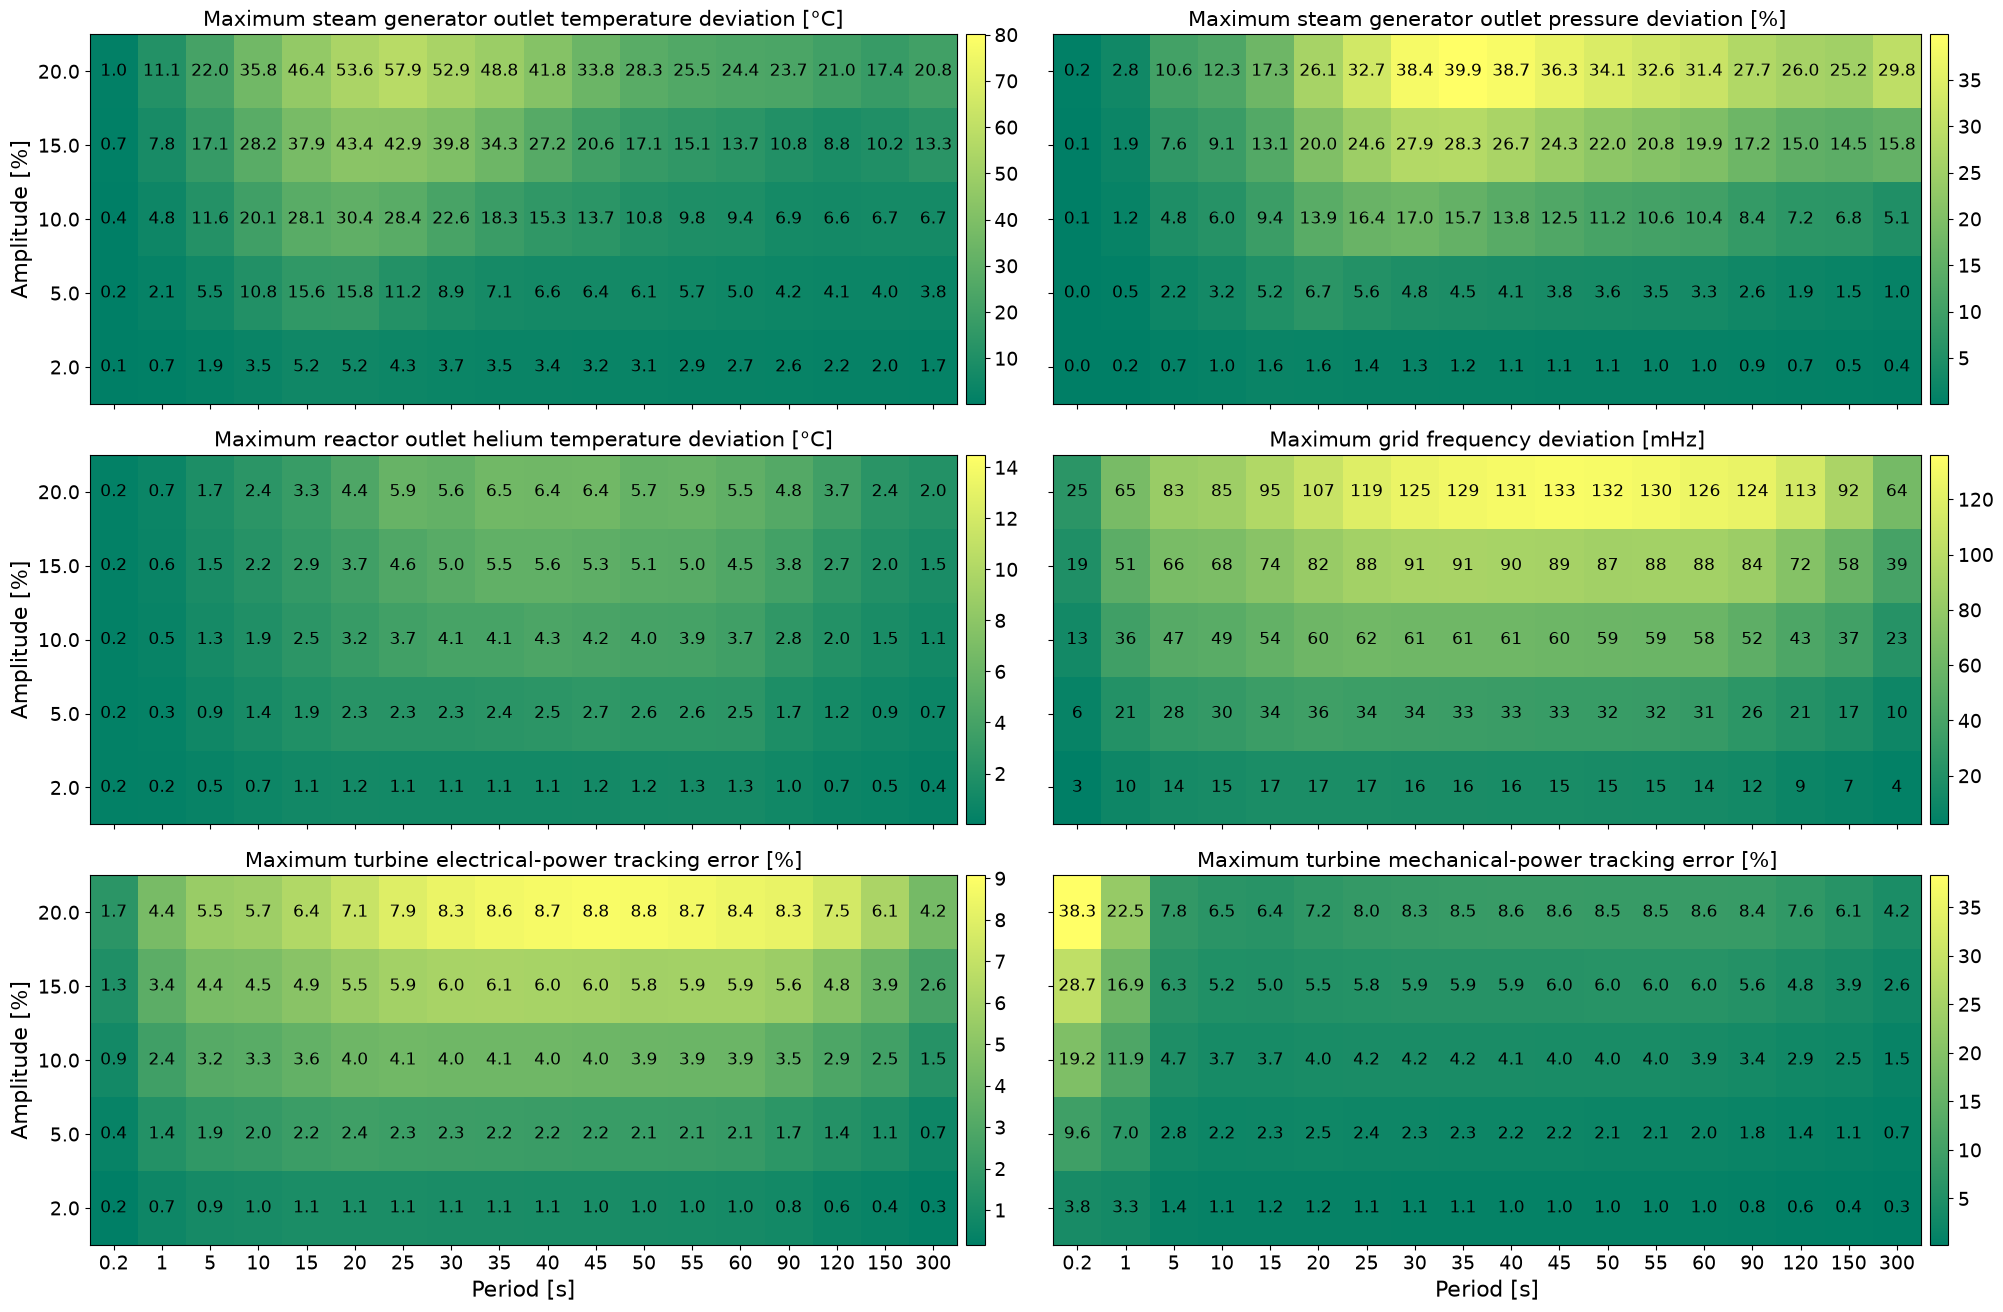

In [10]:
"Generate SMC heatmap figure"

fig, axs = plt.subplots(
    3, 2,
    figsize=(20, 13),
    constrained_layout=True,
    sharex=True,
    sharey=True,
)

fig.set_constrained_layout_pads(
    w_pad=0.08,
    h_pad=0.04,
    wspace=0.03,
    hspace=0.05
)

plots = [
    (T_steam_map_SMC,
     "Maximum steam generator outlet temperature deviation [$\\degree$C]",
     ".1f",
     T_steam_min,
     T_steam_max),

    (P_steam_map_SMC,
     "Maximum steam generator outlet pressure deviation [%]",
     ".1f",
     P_steam_min,
     P_steam_max),

    (T_helium_map_SMC,
     "Maximum reactor outlet helium temperature deviation [$\\degree$C]",
     ".1f",
     T_helium_min,
     T_helium_max),

    (f_grid_map_SMC,
     "Maximum grid frequency deviation [mHz]",
     ".0f",
     f_grid_min,
     f_grid_max),

    (P_elec_map_SMC,
     "Maximum turbine electrical-power tracking error [%]",
     ".1f",
     P_elec_min,
     P_elec_max),

    (P_mech_map_SMC,
     "Maximum turbine mechanical-power tracking error [%]",
     ".1f",
     P_mech_min,
     P_mech_max),
]

for k, (ax, (data, title, fmt, vmin, vmax)) in enumerate(zip(axs.flat, plots)):

    im = ax.imshow(
        data,
        origin="lower",
        aspect="auto",
        cmap="summer",
        vmin=vmin,
        vmax=vmax,
    )

    ax.set_xticks(range(len(PERIOD)))
    ax.set_xticklabels(PERIOD, fontsize=14)

    ax.set_yticks(range(len(AMPLITUDE)))
    ax.set_yticklabels(
        np.array(AMPLITUDE) * 100,
        fontsize=14
    )

    ax.set_title(title, fontsize=15)

    cbar = fig.colorbar(
        im,
        ax=ax,
        pad=0.01
    )

    cbar.ax.tick_params(labelsize=14)
    if k in [4, 5]:
        ax.set_xlabel("Period [s]", fontsize=16)
    if k in [0, 2, 4]:
        ax.set_ylabel("Amplitude [%]", fontsize=16)

    for i in range(len(AMPLITUDE)):
        for j in range(len(PERIOD)):
            ax.text(
                j, i,
                f"{data[i,j]:{fmt}}",
                ha="center",
                va="center",
                fontsize=12,
                color="black"
            )

# fig.savefig("sine_SMC.pdf", bbox_inches="tight")